<a href="https://colab.research.google.com/github/oooinr4018-web/-1/blob/main/ESAA_1113_%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AR 모델

AR 모델:이전 관측 값이 이후 관측 값에 영향을 준다는 아이디어에 대한 모형

시계열 데이터에서 현재 지점 = (과거가 현재에 미치는 영향을 나타내는 모수 X 시계열 데이터의 과거 지점) + (시계열 분석에서의 오차 항 = 백색 잡음)

(p 시점을 기준으로 그 이전의 데이터에 의해 현재 시점의 데이터가 영향을 받는 모형)

MA 모델: 트렌드가 변화하는 상황에 적합한 회귀 모델

: 시계열을 따라 윈도우 크기만큼 슬라이딩 (= 이동 평균 모델)

시계열 데이터에서 현재 시점 = (매개변수 X 과거 시점의 오차) + 오차항

(이전 데이터의 오차에서 현재데이터의 상태 추론)

ARMA 모델: AR, MA를 섞은 모델

(두 가지 관점에서 과거의 데이터 사용)

ARIMA 모델: 자기 회귀, 이동 평균 둘 다 고려한 모델

: 과거 데이터의 선형 관계, 추세까지 고려한 모델

: AROMA(p,d,q) 함수

(p: 자기 회귀 차수, d: 차분 차수, q: 이동 평균 차수)

(fit() -> predict())






In [2]:
pip install statsmodels

/tmp/ipykernel_798/188465808.py:10: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series=read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0], index_col=0,
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   36
Model:                 ARIMA(5, 1, 0)   Log Likelihood                -199.651
Date:                Fri, 13 Nov 2026   AIC                            411.302
Time:                        07:58:41   BIC                            420.634
Sample:                    01-01-1991   HQIC                           414.523
                         - 12-01-1993                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8788      0.227     -3.876      0.000      -1.323      -0.434
ar.L2         -0.2787      0.232     -1.203      0.229      -0.733       0.176
ar.L3         -0.0076      0.270     -0.028      0.9

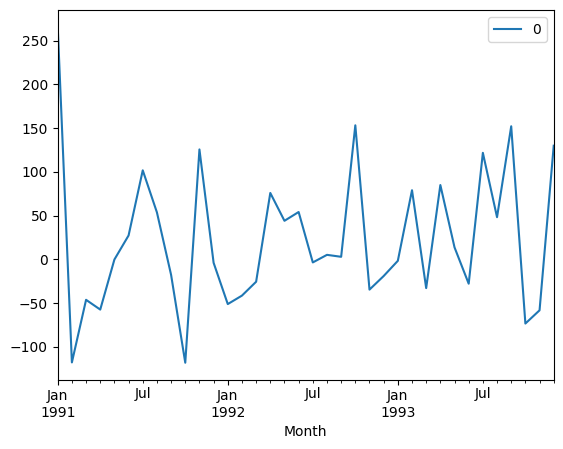

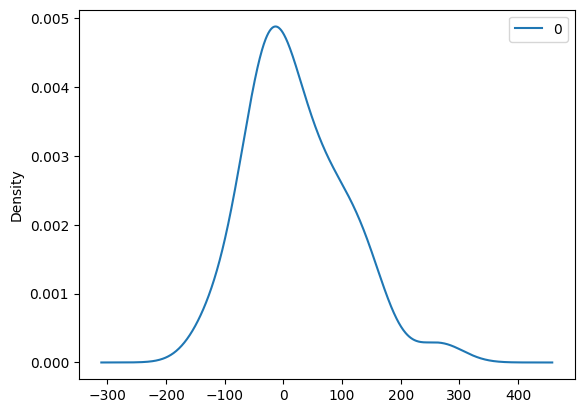

                0
count   36.000000
mean    22.459086
std     82.505331
min   -118.213281
25%    -33.308343
50%      1.361178
75%     76.704967
max    266.000000


In [19]:
# ARIMA() 함수를 호출하여 sales 데이터셋에 대한 예측
from pandas import read_csv
from datetime import datetime
from pandas import DataFrame
from statsmodels.tsa.arima.model import ARIMA
from matplotlib import pyplot

def parser(x): # 시간 표현 함수 정의
  return datetime.strptime('199'+x, '%Y-%m')
series=read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0], index_col=0,
                date_parser=parser)
model=ARIMA(series, order=(5,1,0))
model_fit=model.fit()
print(model_fit.summary())
residuals=DataFrame(model_fit.resid)
residuals.plot()
pyplot.show()
residuals.plot(kind='kde')
pyplot.show()
print(residuals.describe())

/tmp/ipykernel_798/893861565.py:11: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series = read_csv('/content/080289/chap07/data/sales.csv' , header=0, parse_dates=[0], index_col=0, date_parser=parser)


predicted=352.855343, expected=346.300000
predicted=277.398036, expected=329.700000
predicted=368.753734, expected=445.400000
predicted=331.773635, expected=325.900000
predicted=372.070407, expected=449.300000
predicted=360.020872, expected=411.300000
predicted=454.526230, expected=417.400000
predicted=388.690699, expected=545.500000
predicted=437.632447, expected=477.600000
predicted=516.437624, expected=687.000000
predicted=520.916191, expected=435.300000
predicted=675.594647, expected=587.300000
predicted=505.201016, expected=676.900000
Test MSE: 9118.818


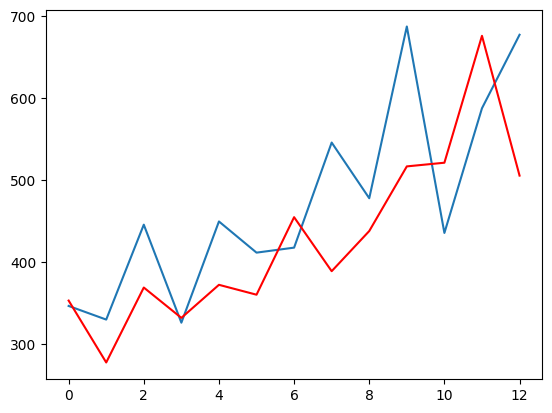

In [31]:
# 코드 7-2. statsmodels 라이브러리를 이용한 sales 데이터셋 예측
import numpy as np
from pandas import read_csv
from datetime import datetime
from matplotlib import pyplot
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
def parser (x) :
  return datetime.strptime('199' +x, '%Y-%m')

series = read_csv('/content/080289/chap07/data/sales.csv' , header=0, parse_dates=[0], index_col=0, date_parser=parser)
X = series.values.flatten()
X = np.nan_to_num(X)
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
predictions = list()
for t in range(len(test)):
  model = ARIMA(history , order=(5,1,0))
  model_fit = model.fit()
  output = model_fit. forecast()
  yhat = output[0]
  predictions.append(yhat)
  obs = test [t]
  history.append(obs)
  print('predicted=%f, expected=%f'% (yhat, obs))
error = mean_squared_error( test, predictions)
print('Test MSE: %.3f' % error)
pyplot.plot(test)
pyplot.plot(predictions, color='red')
pyplot.show()

실제 데이터(빨간색), 모형 실행 결과(파란색) 그림

- 데이터가 우상향 추세 (자전거 판매가 향후에도 계속 증가 예측)


# 7.3. 순환 신경망 (RMN)

RNN: 시간적으로 연속성이 있는 데이터를 처리하려고 고안된 인공 신경망

: 이전 은닉층이 현재 은닉층의 입력이 되면서 반복되는 순환 구조를 갖는다는 의미

: 기억(현재까지 입력 데이터를 요약한 정보)을 가짐 (기존 네트워크와 다른 점)

: 새로운 입력이 네트워크로 들어올 때마다 기억은 조금씩 수정

: 최종적으로 남겨진 기억은 모든 입력 전체를 요약한 정보



RNN 입력, 출력에 따른 유형

- 일대일: 순환 X / ex - 순방향 네트워크

- 일대다: 입력이 하나, 출력이 다수인 구조 / ex - 이미지 캡션 (이미지를 입력해서 이미지에 대한 설명을 문장으로 출력)

- 다대일: 입력이 다수, 출력이 하나인 구조 / ex - 감성 분석기 - 문장 입력, 긍정/부정 출력

self.em = nn.Embedding (len (TEXT . vocab.stoi), embeding_dim) # 임베딩 처리

self. rnn = nn. RNNCell (input_dim, hidden_size) # RNN 적용

self.fc1 = nn.Linear(hidden_size, 256)  # 완전연결층

self.fc2 = nn.Linear(256, 3)  # 출력층

- 다대다: 입력, 출력이 다수인 구조 / ex - 자동 번역기 (언어 번역)

텐서플로:  keras.layers SimpleRNN
(188, return_sequences=True, name='RNN')

-> return_sequences=True 옵션으로 시퀀스 리턴

파이토치: 시스-투-시퀀스 (seq2seq)

- 동기화 다대다: 입력, 출력이 다수인 구조 / ex - 프레임 수준의 비디오 분류 (문장에서 다음에 나올 단어를 예측하는 언어 모델)





# 7.3.1. RNN 계층과 셀

RNN: 내장된 계층, 셀 레벨의 API 제공

RNN 계층: 입렵된 배치 순서대로 모두 처리

: 셀을 래핑하여 동일한 셀을 여러 단계에 적용

셀 유형

- nn.RNNCell: SimpleRNN 계층에 대응되는 RNN 셀

- nn.SPUCell: GPU 계층에 대응되는 CPU 셀

- nn.LSTMCell: LSTM 계층에 대응되는 LSTM 셀

RNN 셀: 오직 하나의 단계만 처리

: RNN 계층의 for loop 구문을 갖는 구조

RNN 계층, 셀 분리해서 설명하는 이유: 파이토치에서 둘을 분리해서 구현하는 것이 가능

RNN 활용 분야: 자연어 처리

(음성 인식, 단어의 의미 판단 및 대화,시계열 데이터 처리(손글씨, 센서 데이터 등)에 활용)



